##Лабораторная работа №3. Кластеризация


Цель работы: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Постановка задачи:

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию методами K-means (K-средних) и DBSCAN;

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров.

5. Исследовать влияние параметров одного из методов на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости).

# Описание датасета

### Описание датасета и его размерность
Для выполнения работы был выбран датасет Palmer Penguins (Пингвины Палмера), содержащий биометрические измерения 344 пингвинов.

Размерность: 344 строки (объекта) и 7 столбцов (признаков).

Типы признаков: 4 числовых признака с плавающей точкой (culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g) и 3 категориальных (species, island, sex).

`culmen_length_mm` — длина надклювья (клюва), измеряется в миллиметрах.
`culmen_depth_mm` — глубина (толщина) надклювья, измеряется в миллиметрах.
`flipper_length_mm` — длина ласты (плавника), измеряется в миллиметрах.
`body_mass_g` — масса тела пингвина, измеряется в граммах.

`species` — биологический вид пингвина (Adelie, Chinstrap, Gentoo). **Является целевой переменной (истинной меткой)**, которая была отделена от матрицы признаков для последующего расчета внешних метрик качества.
`island` — название острова, на котором обитает пингвин (Biscoe, Dream, Torgersen).
`sex` — пол особи (Male / Female).
  

# Необходимые импорты

In [83]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors

from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score
)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

#Дискриптивный анализ

=== 1. Первые 5 строк ===


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE



=== 2. Размерность ===
Строк: 344, Столбцов: 7

=== 3. Типы данных и пропуски ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
None

=== 4. Базовая статистика ===


,count,mean,std,min,25%,50%,75%,max
culmen_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0



=== 5. Гистограммы ===


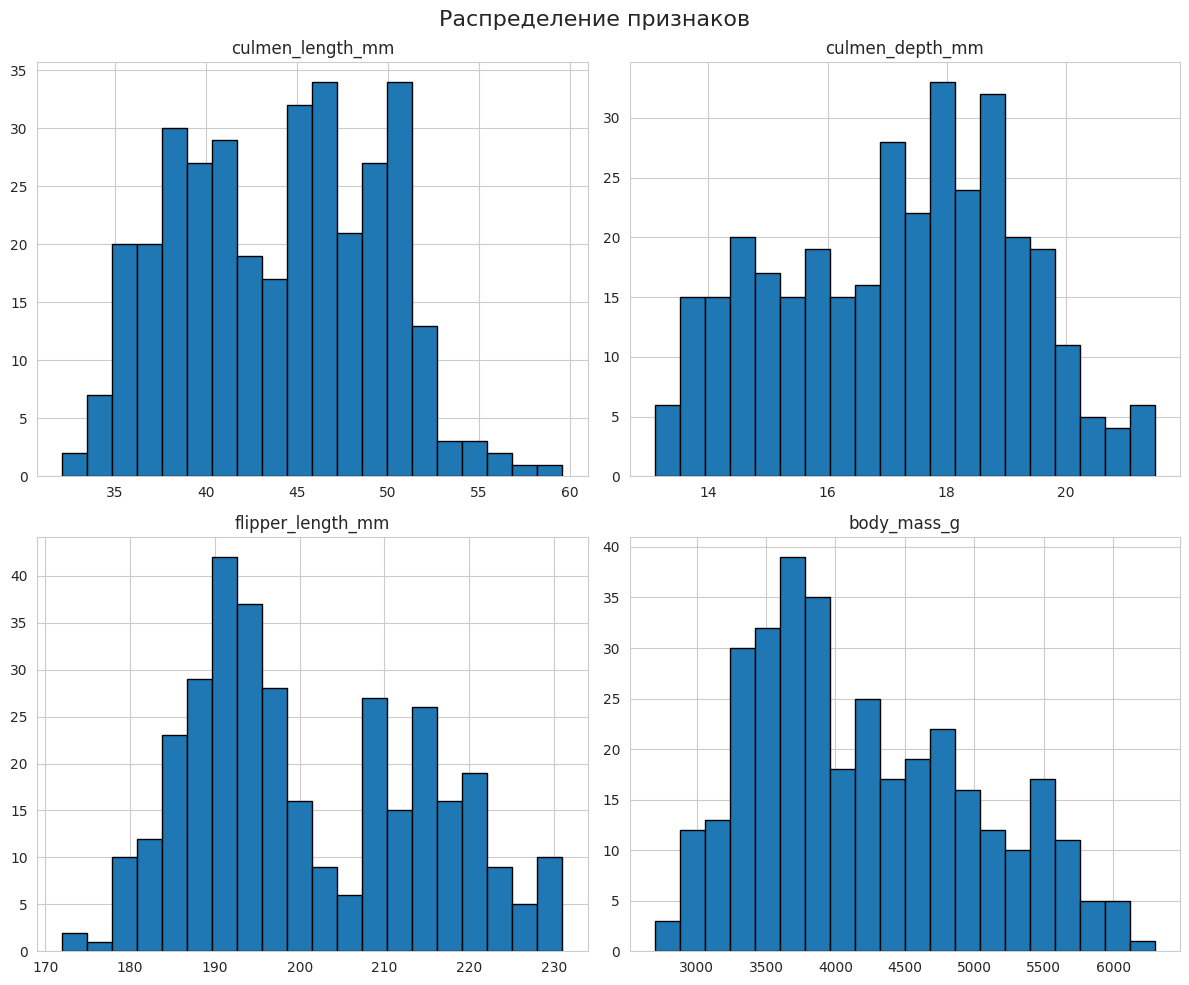

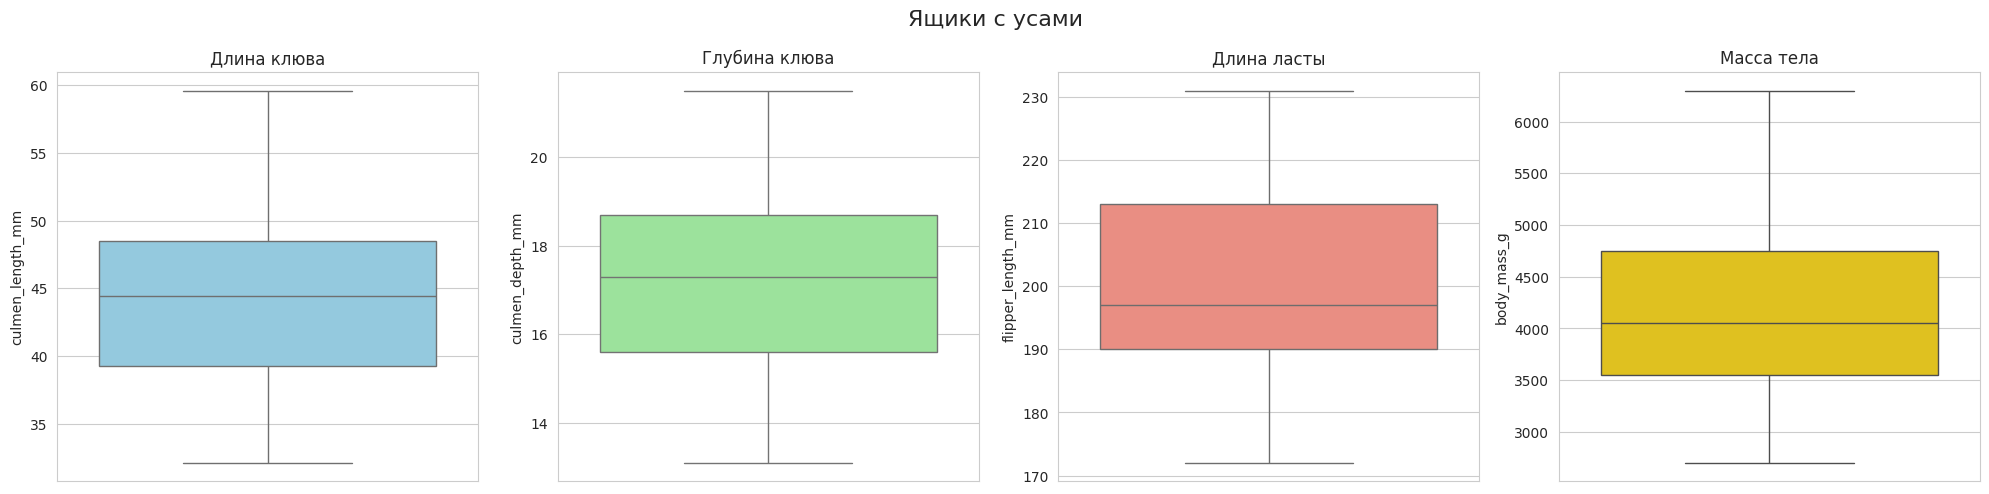

In [84]:
df = pd.read_csv("penguins_size.csv")

print("=== 1. Первые 5 строк ===")
display(df.head())

print("\n=== 2. Размерность ===")
print(f"Строк: {df.shape[0]}, Столбцов: {df.shape[1]}")

print("\n=== 3. Типы данных и пропуски ===")
print(df.info())

print("\n=== 4. Базовая статистика ===")
display(df.describe().T)

print("\n=== 5. Гистограммы ===")
df.hist(figsize=(12, 10), bins=20, edgecolor='black')
plt.suptitle('Распределение признаков', fontsize=16)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 4, figsize=(20, 5))

sns.boxplot(y=df['culmen_length_mm'], ax=axes[0], color='skyblue')
axes[0].set_title('Длина клюва')

sns.boxplot(y=df['culmen_depth_mm'], ax=axes[1], color='lightgreen')
axes[1].set_title('Глубина клюва')

sns.boxplot(y=df['flipper_length_mm'], ax=axes[2], color='salmon')
axes[2].set_title('Длина ласты')

sns.boxplot(y=df['body_mass_g'], ax=axes[3], color='gold')
axes[3].set_title('Масса тела')

plt.suptitle('Ящики с усами', fontsize=16)
plt.tight_layout()
plt.show()

 # Анализ распределения признаков

Для визуальной оценки формы распределения признаков были построены гистограммы. Анализ графиков позволяет сделать следующие выводы:

Ни один из четырех числовых признаков не подчиняется нормальному закону распределения,

Признаки culmen_length_mm (длина клюва) и body_mass_g (масса тела) имеют ярко выраженную бимодальную структуру.

Распределение признака flipper_length_mm (длина ласты) имеет левостороннюю асимметрию, а culmen_depth_mm (глубина клюва) — правостороннюю.

Вывод: Так как распределения не являются нормальными, для кластеризации целесообразно использовать непараметрические методы (K-means, DBSCAN), не требующие нормальности данных.

In [85]:

X = df[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y_true = df['species']

imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)
X_imputed_df = pd.DataFrame(X_imputed, columns=X.columns)

print("\nПропуски в X после обработки:")
print(X_imputed_df.isnull().sum())

display(X_imputed_df.head())


Пропуски в X после обработки:
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
dtype: int64


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,39.10,18.7,181.0,3750.0
1,39.50,17.4,186.0,3800.0
2,40.30,18.0,195.0,3250.0
3,44.45,17.3,197.0,4050.0
4,36.70,19.3,193.0,3450.0


#Анализ пропусков

С помощью df.info() было выявлено наличие пропусков:

В числовых признаках (размеры) по 2 пропуска (342 значения из 344).

В категориальном признаке sex — 10 пропусков.
Обработка: Числовые пропуски были заполнены медианой с помощью SimpleImputer(strategy='median'). Категориальные признаки (species, island, sex) были исключены из матрицы признаков X.

species (вид): Исключен, так как является целевой переменной (меткой класса).Колонка сохранена в отдельной переменной y_true для последующего расчета внешних метрик.

island (остров обитания) и sex (пол): Исключены, так как являются категориальными признаками. Методы K-means и DBSCAN основаны на вычислении Евклидова расстояния между числовыми векторами. Они не умеют вычислять расстояние между значениями «Female» и «Male» или «Torgersen» и «Biscoe».

Если перевести пол или остров в числа (0 и 1), алгоритм будет воспринимать это как геометрическую координату, равную по весу размеру клюва. Это создаст искусственные «разрывы» в пространстве и исказит кластеры, которые должны строиться на основе физических размеров. Так как цель — кластеризация по биометрии (размерам), эти категориальные признаки удаляются.

#Нормализация и диаграммы рассеивания

Результаты масштабирования
      culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
mean              -0.0              0.0                0.0          0.0
std                1.0              1.0                1.0          1.0


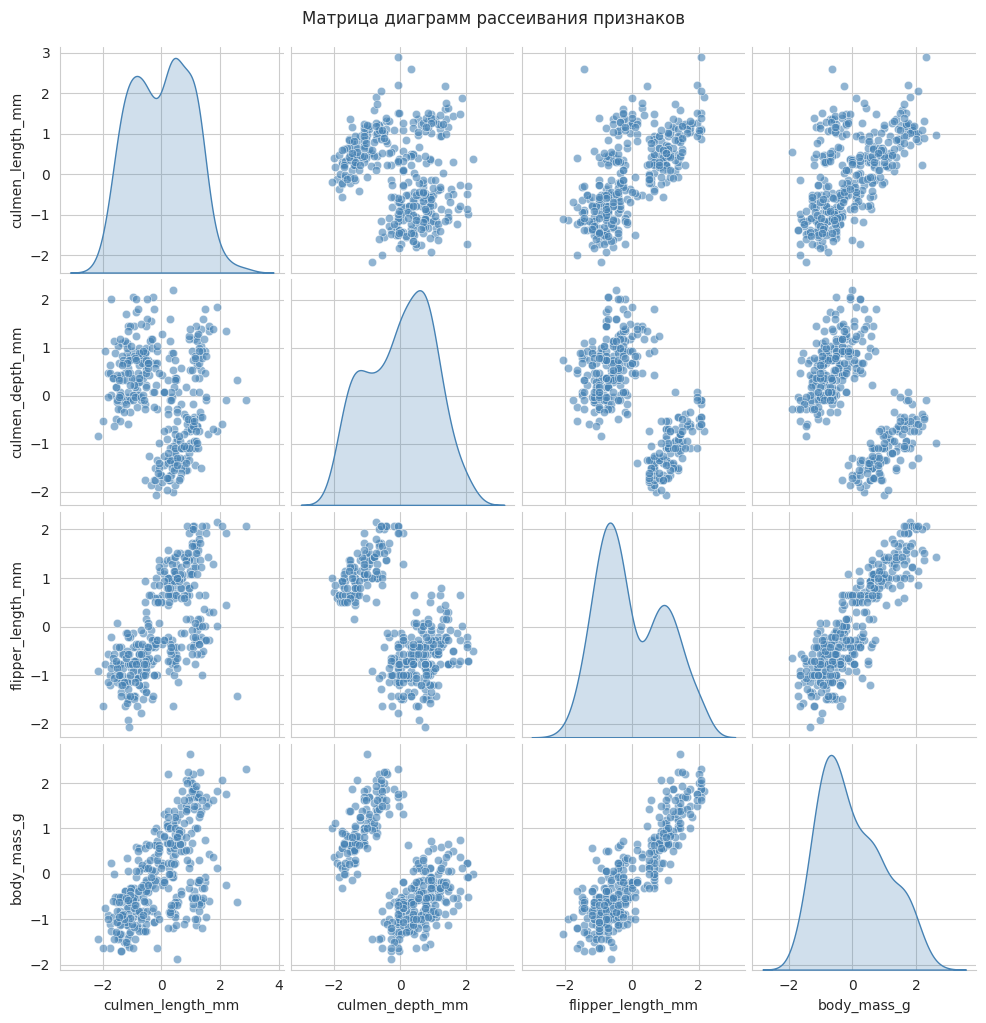

In [86]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed_df)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_imputed_df.columns)

print("Результаты масштабирования")
print(X_scaled_df.describe().loc[['mean', 'std']].round(2))

sns.pairplot(
    X_scaled_df,
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 'color': 'steelblue'},
    diag_kws={'color': 'steelblue'}
)
plt.suptitle('Матрица диаграмм рассеивания признаков', y=1.02)
plt.show()

### Анализ матрицы диаграмм рассеивания

Перед построением матрицы диаграмм рассеивания была выполнена **нормализация (стандартизация)** числовых признаков с помощью `StandardScaler`. Это позволило привести все признаки (измеряемые в миллиметрах и граммах) к единому масштабу.

**1. Визуальная оценка структуры данных:**
Анализируя диаграммы рассеивания, можно сделать следующие выводы:
*   **Отсутствие равномерности:** Точки распределены неравномерно. Нет хаотичного разброса по всему пространству, что говорит о наличии скрытой структуры.
*   **Форма и плотность:** На графиках четко прослеживаются плотные сгустки («облака») точек. Некоторые из них имеют форму, близкую к **кругам/эллипсам** (например, при сравнении `culmen_length_mm` и `culmen_depth_mm`). Другие пары признаков образуют вытянутые **«ленты»** (например, `flipper_length_mm` и `body_mass_g`), что объясняется сильной корреляцией этих признаков.
*   **Предположительное количество кластеров:** В двумерных проекциях визуально выделяются как минимум 2-3 крупных изолированных сгустка. Исходя из этого, можно предположить наличие **2 или 3 кластеров**.

**2. Аргументация выбора методов кластеризации:**

*   **K-means:**
    Наличие четких, плотных и изолированных «круглых» или эллиптических сгустков является идеальной предпосылкой для K-means. Мы предполагаем, что центры этих сгустков будут устойчивыми.
    
*   **DBSCAN:**
    Хотя структура содержит четкие ядра, на графиках также видны вытянутые «ленты» и разреженные области между основными сгустками. Кроме того, в данных присутствуют единичные точки (выбросы), которые могут быть далеко от основных масс. K-means будет «тянуть» центры к этим выбросам. **DBSCAN** же, будучи плотностным алгоритмом, сможет выделить эти вытянутые структуры (он не ограничен формой шара) и автоматически пометит разреженные точки на границах или вдали от сгустков как шум, не искажая общую картину.


# Метод K-means
### Определение оптимального k

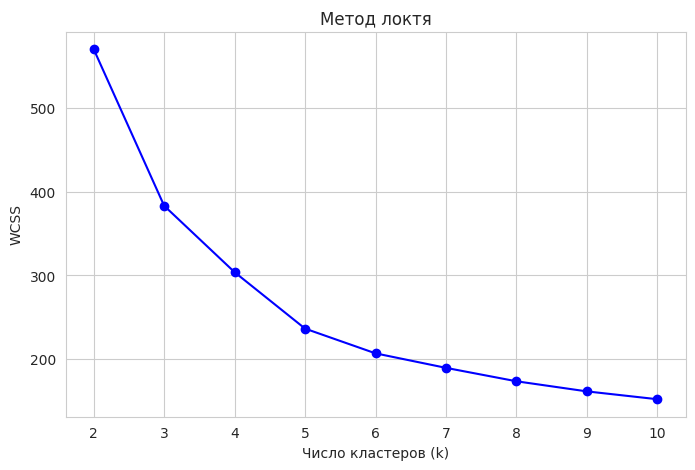

In [87]:
inertia = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_scaled_df)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', color='blue')
plt.title('Метод локтя')
plt.xlabel('Число кластеров (k)')
plt.ylabel('WCSS')
plt.xticks(K_range)
plt.grid(True)
plt.show()

На графике метода локтя не наблюдается ярко выраженного излома, выбор оптимального числа кластеров продолжим с помощью анализа силуэта:

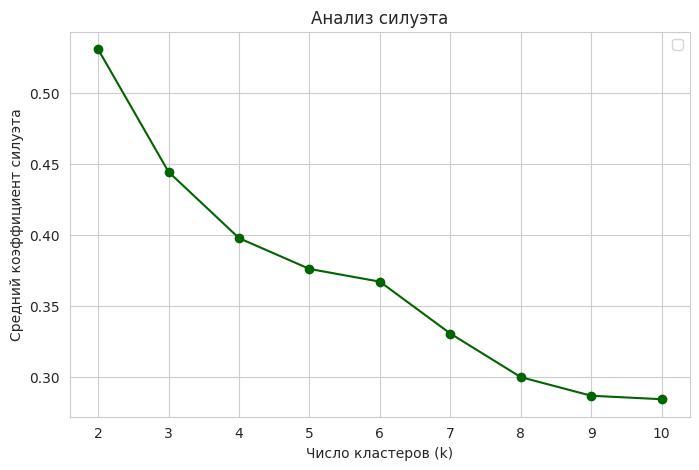

Оптимальное число кластеров по силуэту: 2
Максимальный средний силуэт: 0.531


In [88]:
silhouette_vals = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled_df)
    score = silhouette_score(X_scaled_df, labels)
    silhouette_vals.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_vals, marker='o', color='darkgreen')
plt.title('Анализ силуэта')
plt.xlabel('Число кластеров (k)')
plt.ylabel('Средний коэффициент силуэта')
plt.xticks(K_range)
plt.grid(True)

best_k = K_range[silhouette_vals.index(max(silhouette_vals))]
plt.legend()
plt.show()

print(f"Оптимальное число кластеров по силуэту: {best_k}")
print(f"Максимальный средний силуэт: {max(silhouette_vals):.3f}")

Строгий анализ силуэта показал, что математически оптимальным является разбиение на \(K=2\).

# Вывод метрик:

In [89]:
def print_clustering_metrics(X, labels, y_true=None, method_name="Метод"):
    unique_labels = set(labels)

    if -1 in unique_labels:
        print(f"=== Метрики для {method_name} (без учета шума) ===")
        mask = labels != -1
        X_eval = X[mask]
        labels_eval = labels[mask]
        if y_true is not None:
            y_true_eval = y_true[mask]
    else:
        print(f"=== Метрики для {method_name} ===")
        X_eval = X
        labels_eval = labels
        if y_true is not None:
            y_true_eval = y_true

    n_clusters = len(set(labels_eval))

    if n_clusters < 2:
        print("Ошибка: найдено меньше 2 кластеров.")
        return

    sil = silhouette_score(X_eval, labels_eval)
    ch = calinski_harabasz_score(X_eval, labels_eval)
    db = davies_bouldin_score(X_eval, labels_eval)

    print(f"Silhouette Score: {sil:.3f}")
    print(f"Calinski-Harabasz Index: {ch:.3f}")
    print(f"Davies-Bouldin Index: {db:.3f}")

    if y_true is not None:
        ari = adjusted_rand_score(y_true_eval, labels_eval)
        ri = rand_score(y_true_eval, labels_eval)
        print(f"Adjusted Rand Index (ARI): {ari:.3f}")
        print(f"Rand Index: {ri:.3f}")

# Запуск k-means:

In [90]:
kmeans_k2 = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
kmeans_labels_k2 = kmeans_k2.fit_predict(X_scaled_df)

print_clustering_metrics(X_scaled_df, kmeans_labels_k2, y_true, method_name="K-means (K=2)")

kmeans_centers_orig_k2 = scaler.inverse_transform(kmeans_k2.cluster_centers_)
centers_df_k2 = pd.DataFrame(kmeans_centers_orig_k2, columns=X_imputed_df.columns)
print("\nЦентры кластеров K=2 (в исходных единицах):")

centers = kmeans_k2.cluster_centers_

distances_to_centers = cdist(X_scaled_df, centers, metric='euclidean')
min_distances = np.min(distances_to_centers, axis=1)

mean_intra_distance = np.mean(min_distances)

inter_centers_distance = cdist(centers, centers, metric='euclidean')

print(f"Среднее внутрикластерное расстояние (компактность): {mean_intra_distance:.3f}")
print("Матрица расстояний между центрами кластеров:")
print(np.round(inter_centers_distance, 3))
display(centers_df_k2)

kmeans_k3 = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)
kmeans_labels_k3 = kmeans_k3.fit_predict(X_scaled_df)

=== Метрики для K-means (K=2) ===
Silhouette Score: 0.531
Calinski-Harabasz Index: 482.748
Davies-Bouldin Index: 0.715
Adjusted Rand Index (ARI): 0.646
Rand Index: 0.819

Центры кластеров K=2 (в исходных единицах):
Среднее внутрикластерное расстояние (компактность): 1.185
Матрица расстояний между центрами кластеров:
[[0.    3.193]
 [3.193 0.   ]]


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,41.932579,18.359729,191.823529,3713.800905
1,47.504878,14.982114,217.186992,5076.016260


## Выводы
Анализ расстояний в отмасштабированном пространстве показал, что среднее внутрикластерное расстояние (компактность) составляет **1.185**, а расстояние между центрами кластеров — **3.193**.
Превышение межкластерного расстояния над внутрикластерным почти в 3 раза свидетельствует о высокой степени разделимости групп. Точки плотно сгруппированы вокруг своих центров, а сами центры находятся далеко друг от друга.

*   **Внутренние метрики:** Silhouette (0.531), Calinski-Harabasz (482.7) и Davies-Bouldin (0.715) подтверждают высокое качество геометрии кластеров.
*   **Silhouette Score (0.531):** Метрика лежит в диапазоне от -1 до 1, где значения выше 0.5 считаются индикатором сильной, хорошо различимой структуры. Значение 0.531 означает, что в среднем объект находится значительно ближе к точкам своего кластера, чем к точкам ближайшего чужого кластера. Кластеры плотные и четко отделены друг от друга.
*   **Calinski-Harabasz Index (482.7):** Данная метрика (отношение дисперсии между кластерами к дисперсии внутри кластеров) не имеет верхней границы, поэтому оценивается относительно. Значение 482.7 является высоким показателем, что свидетельствует о том, что разброс между центрами групп значительно превышает разброс точек внутри каждой группы.
*   **Davies-Bouldin Index (0.715):** Метрика измеряет среднее сходство между кластерами (отношение разброса внутри кластера к расстоянию между центрами). Идеальное значение — 0. Значение 0.715 (меньше 1) говорит о том, что кластеры не накладываются друг на друга, а их центры достаточно удалены.
*   **Внешние метрики:** Adjusted Rand Index (ARI) = 0.646. Алгоритм без учителя смог восстановить реальную биологическую структуру на 64.6%.

**Содержательная интерпретация:**
Центры кластеров в исходных единицах измерения четко делят пингвинов на две группы:
*   **Кластер 0 (средние):** Масса ~3.7 кг, длина ласты ~192 мм, клюв ~42 мм.
*   **Кластер 1 (крупные):** Масса ~5 кг, длина ласты ~217 мм, клюв ~47.5 мм.

Алгоритм K-means успешно справился с задачей, найдя математически оптимальное разбиение на 2 кластера (\(K=2\)). Однако, поскольку в реальности видов три, K-means объединил два близких по размерам вида в один кластер, что подтверждается значением ARI (0.646, а не 1.0).

#DBSCAN

### Обоснование параметров DBSCAN (m и ϵ)

Параметр \(m\) (минимальное количество точек в окрестности) обычно выбирается в диапазоне от 3 до 9. Чем более неоднородный датасет и чем выше уровень шума, тем большим должно быть значение \(m\).
В нашем случае датасет содержит 4 числовых признака. Стандартной эвристикой для многомерных данных является правило \(m = \text{число признаков} + 1\). Таким образом, было выбрано значение **\(m = 5\)**. Это значение предотвращает создание ложных кластеров из случайных выбросов, но при этом достаточно мало, чтобы не игнорировать реальные плотные группы.


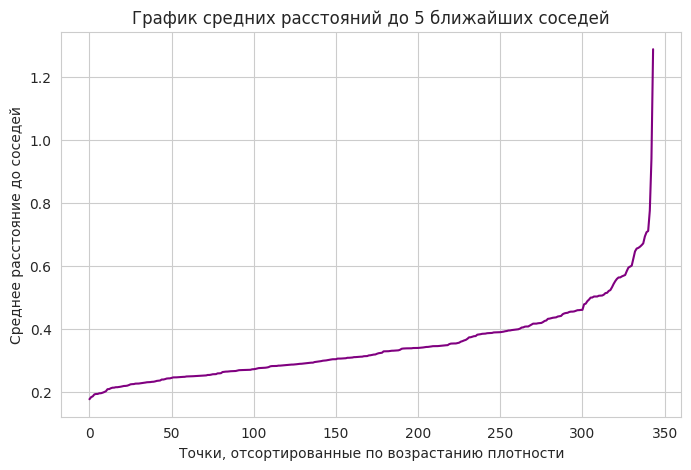

In [91]:
m = 5
neighbors = NearestNeighbors(n_neighbors=m)
neighbors_fit = neighbors.fit(X_scaled_df)
distances, indices = neighbors_fit.kneighbors(X_scaled_df)

mean_distances = np.mean(distances, axis=1)

sorted_mean_distances = np.sort(mean_distances)

plt.figure(figsize=(8, 5))
plt.plot(sorted_mean_distances, color='purple')
plt.title(f'График средних расстояний до {m} ближайших соседей')
plt.xlabel('Точки, отсортированные по возрастанию плотности')
plt.ylabel('Среднее расстояние до соседей')
plt.grid(True)
plt.show()

**2. Выбор параметра ϵ на основе графика:**
Для подбора радиуса окрестности ϵ был использован метод построения графика средних расстояний до \(m\)-ближайших соседей (в нашем случае до 5-ти).
*   По оси X отложены все точки, отсортированные по возрастанию их плотности.
*   По оси Y отложено среднее расстояние до 5 ближайших соседей для каждой точки.

**Анализ графика:**
На графике видно, что примерно до 300-й точки линия растет очень плавно (значения от 0.18 до 0.45). Это означает, что данные точки находятся в плотных областях.
Однако после 300-й точки график начинает резко загибаться вверх. В районе 320–330-й точки значения достигают **0.5 – 0.6**, после чего линия взмывает почти вертикально.

**Вывод:**
Точка самого сильного перегиба находится в диапазоне **0.5 – 0.6**. Принимаем **\(ϵ = 0.6\)**.
*   Если взять ϵ меньше 0.5, мы отсечем слишком много нормальных точек, увеличивая шум.
*   Если взять ϵ больше 0.7, алгоритм начнет склеивать между собой разные кластеры, так как радиус окрестности станет слишком большим для наших данных.

# Запуск DBSCAN

In [92]:
dbscan = DBSCAN(eps=0.6, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled_df)

n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_ = list(dbscan_labels).count(-1)

print(f"Параметры: eps=0.6, min_samples=5")
print(f"Количество выделенных кластеров: {n_clusters_}")
print(f"Количество шумовых объектов: {n_noise_} ({n_noise_ / len(dbscan_labels) * 100:.1f}%)")

print_clustering_metrics(X_scaled_df, dbscan_labels, y_true, method_name="DBSCAN")

Параметры: eps=0.6, min_samples=5
Количество выделенных кластеров: 2
Количество шумовых объектов: 34 (9.9%)
=== Метрики для DBSCAN (без учета шума) ===
Silhouette Score: 0.557
Calinski-Harabasz Index: 517.230
Davies-Bouldin Index: 0.670
Adjusted Rand Index (ARI): 0.666
Rand Index: 0.830


# Выводы
### Интерпретация результатов базового прогона DBSCAN

Параметры: `eps = 0.6`, `min_samples = 5`.
Алгоритм выделил **2 кластера** и нашел **34 шумовых объекта** (9.9% от выборки).

**Анализ метрик (сравнение с K-means):**
*   **Silhouette Score (0.557):** Значение выше, чем у K-means (0.531). Это объясняется тем, что DBSCAN исключил 10% выбросов (шум), которые в K-means тянули центры кластеров на себя и ухудшали компактность. Оставшиеся 90% точек образуют очень плотные ядра.
*   **Calinski-Harabasz Index (517.2):** Также выше, чем у K-means (482.7), что подтверждает лучшую разделимость «очищенных» кластеров.
*   **Davies-Bouldin Index (0.670):** Ниже, чем у K-means (0.715). Кластеры стали еще более компактными и далекими друг от друга.
*   **Adjusted Rand Index (ARI = 0.666):** DBSCAN чуть лучше справился с восстановлением биологической структуры по сравнению с K-means (0.646). Он правильно выделил крупных пингвинов (Генту) и объединил мелких/средних (Адели и Чинстрап).

**Пространственные характеристики:**
Для алгоритма DBSCAN расчет расстояний между центрами кластеров не является информативным, так как алгоритм не вычисляет центроиды. Однако внутренние метрики (Silhouette, Davies-Bouldin) подтверждают, что кластеры плотные и хорошо разделены.

**Вывод:**
Хотя биологически в датасете 3 вида, геометрически в 4-мерном пространстве признаков два вида (Адели и Чинстрап) образуют единое непрерывное плотное «облако». Ни K-means, ни DBSCAN не могут найти между ними границу без использования истинных меток классов (обучения с учителем). DBSCAN, тем не менее, показал себя лучше: он корректно выделил 10% аномалий (шум), которые являются пингвинами с аномальными размерами.

# Исследование влияния k на качество K-means

Для исследования влияния k на качество кластеризации, мы выделим столбец относительной разницы с эталонным значением (дельта - разность).

In [93]:
results = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled_df)

    sil = silhouette_score(X_scaled_df, labels)
    ch = calinski_harabasz_score(X_scaled_df, labels)
    db = davies_bouldin_score(X_scaled_df, labels)
    ari = adjusted_rand_score(y_true, labels)
    ri = rand_score(y_true, labels)

    results.append({
        'K': k,
        'Silhouette': sil,
        'Calinski-Harabasz': ch,
        'Davies-Bouldin': db,
        'ARI': ari,
        'Rand Index': ri
    })

df_results = pd.DataFrame(results)

df_results['Δ Silhouette'] = df_results['Silhouette'].diff()
df_results['Δ ARI'] = df_results['ARI'].diff()

display(df_results.round(3))

,K,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI,Rand Index,Δ Silhouette,Δ ARI
0,2,0.531,482.748,0.715,0.646,0.819,NaN,NaN
1,3,0.444,441.535,0.948,0.780,0.900,-0.086,0.135
2,4,0.398,399.846,0.947,0.626,0.836,-0.047,-0.154
3,5,0.376,408.540,0.976,0.566,0.818,-0.022,-0.060
4,6,0.367,382.150,0.994,0.526,0.804,-0.009,-0.041
5,7,0.330,351.722,1.058,0.485,0.790,-0.037,-0.041
6,8,0.300,332.866,1.141,0.402,0.762,-0.031,-0.083
7,9,0.287,315.286,1.189,0.345,0.742,-0.013,-0.057
8,10,0.284,298.938,1.214,0.316,0.733,-0.002,-0.029


### Анализ влияния параметра K на качество K-means

Результаты перебора k от 2 до 10:

**1. Анализ внутренних метрик:**
С точки зрения математики, наилучшим является \(K=2\) (максимальный Silhouette 0.531). С дальнейшим ростом \(K\) метрики ухудшаются: Silhouette и Calinski-Harabasz плавно падают, а Davies-Bouldin растет.
Ухудшение метрик происходит плавно, без резких обвалов. Это объясняется тем, что в данных всего три естественные группы. При \(K > 3\) алгоритм не находит новую структуру, а начинает искусственно дробить уже существующие плотные кластеры на части, минимизируя локальные расстояния (переобучение).

**2. Анализ внешних метрик:**
Здесь наблюдается пик при **\(K=3\)**. Значение ARI резко возрастает с 0.646 (при K=2) до **0.780** (при K=3), а Rand Index достигает 0.900.
Это происходит потому, что при \(K=3\) алгоритм наконец-то разделяет два похожих вида (Адели и Чинстрап), которые при \(K=2\) были слиты воедино. Дальнейшее увеличение \(K\) (до 4, 5 и т.д.) разрывает реальные виды на части, из-за чего ARI и Rand Index закономерно падают.

**Итог:**
Эксперимент наглядно демонстрирует конфликт между «математической геометрией» и «реальным смыслом». С точки зрения чистых расстояний (\(K=2\)) данные делятся лучше. Но с точки зрения предметной области (биологии) оптимальным является \(K=3\). Для дальнейшего анализа и сравнения с DBSCAN мы зафиксируем оба результата.

# Визуализация полученных кластеров в пространстве признаков

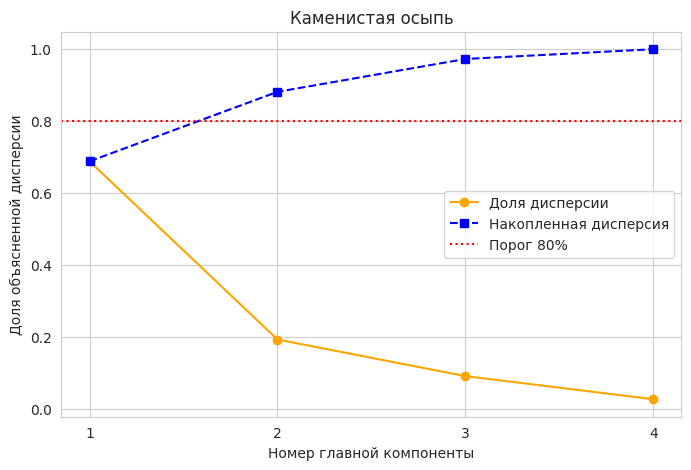

Компонента 1: 68.84%
Компонента 2: 19.31%
Компонента 3: 9.14%
Компонента 4: 2.71%
Суммарно 2 компоненты объясняют: 88.15% дисперсии


In [94]:
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled_df)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 5), pca_full.explained_variance_ratio_, marker='o', color='orange', label='Доля дисперсии')
plt.plot(range(1, 5), np.cumsum(pca_full.explained_variance_ratio_), marker='s', color='blue', linestyle='--', label='Накопленная дисперсия')
plt.title('Каменистая осыпь')
plt.xlabel('Номер главной компоненты')
plt.ylabel('Доля объясненной дисперсии')
plt.xticks(range(1, 5))
plt.axhline(y=0.8, color='red', linestyle=':', label='Порог 80%')
plt.legend()
plt.grid(True)
plt.show()

for i, ratio in enumerate(pca_full.explained_variance_ratio_, 1):
    print(f"Компонента {i}: {ratio*100:.2f}%")
print(f"Суммарно 2 компоненты объясняют: {sum(pca_full.explained_variance_ratio_[:2])*100:.2f}% дисперсии")

По графику Scree Plot видно, что первая главная компонента (PC1) объясняет **68.84%** дисперсии, а вторая (PC2) — **19.31%**. Суммарно две компоненты объясняют **88.15%** дисперсии, что значительно превышает стандартный порог в 80%. Это означает, что мы можем визуализировать данные в 2D-пространстве без существенной потери информации. Остальные две компоненты (около 12%) можно отбросить, так как они несут преимущественно шум.

# Интерпретация компонент:

Веса (нагрузки) признаков в компонентах:


,PC1,PC2
culmen_length_mm,0.455,0.597
culmen_depth_mm,-0.400,0.798
flipper_length_mm,0.576,0.002
body_mass_g,0.548,0.084



Вклад каждого признака в компоненту (в %):


,PC1,PC2
culmen_length_mm,20.72,35.67
culmen_depth_mm,16.03,63.61
flipper_length_mm,33.18,0.00
body_mass_g,30.07,0.71


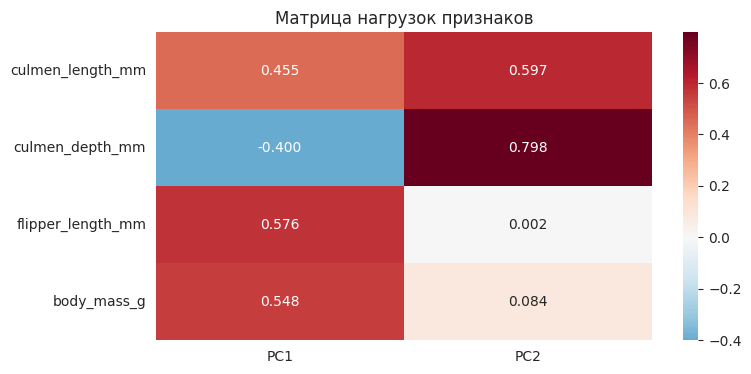

In [95]:
loadings_df = pd.DataFrame(
    pca_full.components_[:2].T,
    columns=['PC1', 'PC2'],
    index=X_scaled_df.columns
)

loadings_percent = (loadings_df**2 / (loadings_df**2).sum()) * 100

print("Веса (нагрузки) признаков в компонентах:")
display(loadings_df.round(3))

print("\nВклад каждого признака в компоненту (в %):")
display(loadings_percent.round(2))

plt.figure(figsize=(8, 4))
sns.heatmap(loadings_df, annot=True, cmap='RdBu_r', center=0, fmt=".3f")
plt.title('Матрица нагрузок признаков')
plt.show()

*   **Первая главная компонента (PC1)** объясняет 68.84% дисперсии. Наибольший вклад в неё вносят длина ласты (33.18%) и масса тела (30.07%), которые имеют высокие положительные нагрузки. Глубина клюва имеет отрицательную нагрузку (-0.400). Это означает, что данная ось описывает общие габариты птицы. Присвоим ей название **«Общий размер и масса»**.
*   **Вторая главная компонента (PC2)** объясняет 19.31% дисперсии и практически полностью игнорирует размеры тела (вклад массы и ласты менее 1%). Она формируется исключительно за счет параметров клюва: глубина (вклад 63.61%) и длина (вклад 35.67%). Эту компоненту можно назвать **«Форма и размер клюва»**.

Таким образом, при визуализации в пространстве PC1-PC2, смещение точки вправо/влево будет указывать на изменение размера пингвина, а смещение вверх/вниз — на изменение пропорций его клюва.

# Визуализация полученных кластеров

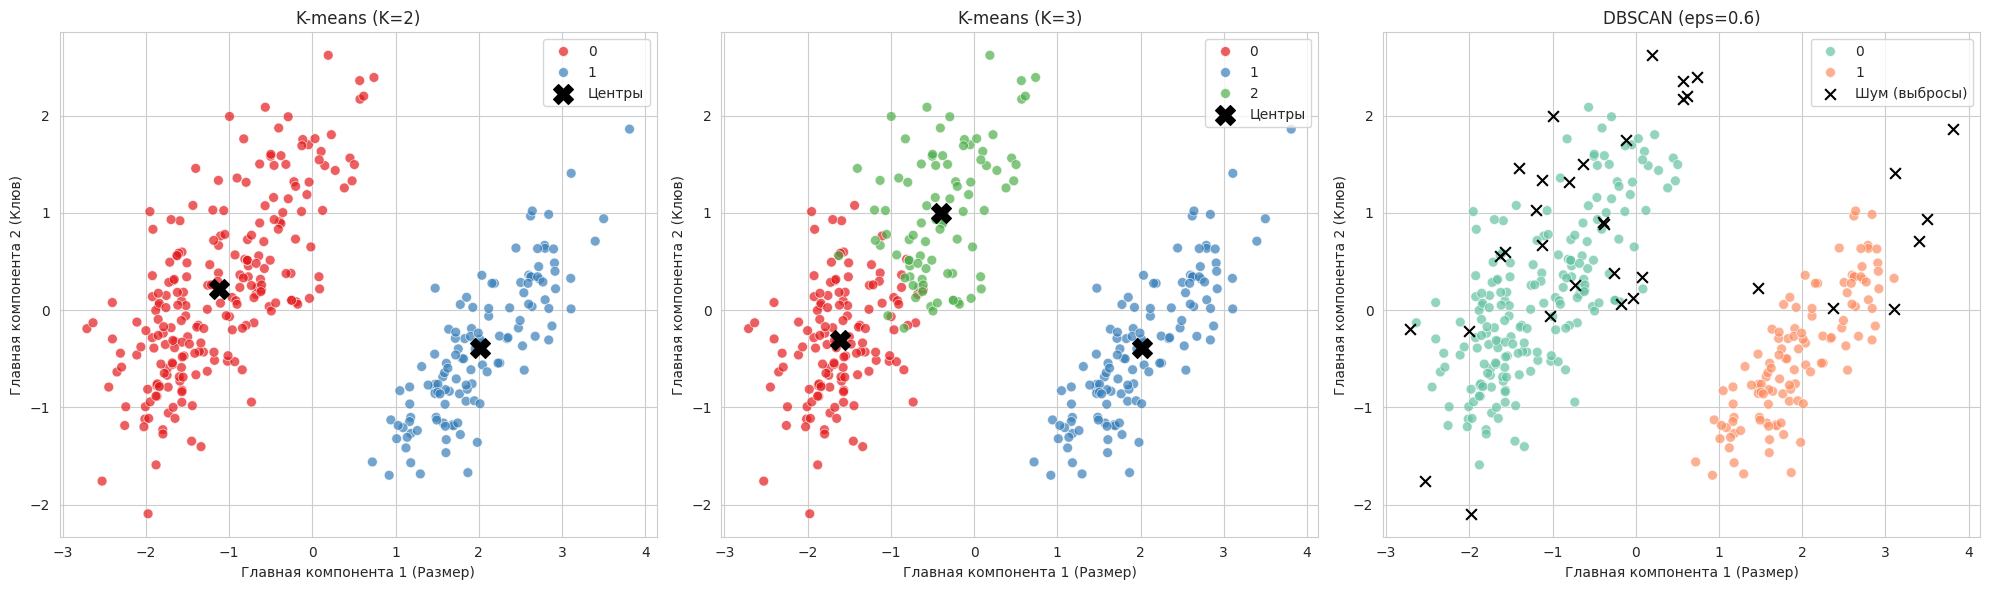

In [96]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_df)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels_k2, palette='Set1', ax=axes[0], s=50, alpha=0.7)
centers_pca_k2 = pca.transform(kmeans_k2.cluster_centers_)
axes[0].scatter(centers_pca_k2[:, 0], centers_pca_k2[:, 1], c='black', marker='X', s=200, label='Центры')
axes[0].set_title('K-means (K=2)')
axes[0].set_xlabel('Главная компонента 1 (Размер)')
axes[0].set_ylabel('Главная компонента 2 (Клюв)')
axes[0].legend()

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels_k3, palette='Set1', ax=axes[1], s=50, alpha=0.7)
centers_pca_k3 = pca.transform(kmeans_k3.cluster_centers_)
axes[1].scatter(centers_pca_k3[:, 0], centers_pca_k3[:, 1], c='black', marker='X', s=200, label='Центры')
axes[1].set_title('K-means (K=3)')
axes[1].set_xlabel('Главная компонента 1 (Размер)')
axes[1].set_ylabel('Главная компонента 2 (Клюв)')
axes[1].legend()

sns.scatterplot(x=X_pca[dbscan_labels != -1, 0], y=X_pca[dbscan_labels != -1, 1], hue=dbscan_labels[dbscan_labels != -1], palette='Set2', ax=axes[2], s=50, alpha=0.7)
axes[2].scatter(X_pca[dbscan_labels == -1, 0], X_pca[dbscan_labels == -1, 1], c='black', marker='x', s=60, label='Шум (выбросы)')
axes[2].set_title('DBSCAN (eps=0.6)')
axes[2].set_xlabel('Главная компонента 1 (Размер)')
axes[2].set_ylabel('Главная компонента 2 (Клюв)')
axes[2].legend()

plt.tight_layout()
plt.show()

### Выводы по всем методам

**Интерпретация выделенных групп:**
Анализ графиков в пространстве главных компонент (где PC1 — «Размер», PC2 — «Форма клюва») позволяет дать следующим образом описать группы:
*   **Группа «Крупные» (правый кластер):** Характеризуется высокими значениями PC1. Это пингвины вида Генту — с большой массой тела и длинными ластами. Оба метода (и K-means, и DBSCAN) выделили эту группу безошибочно.
*   **Группа «Мелкие/Средние» (левый кластер):** Характеризуется низкими значениями PC1. При \(K=2\) (K-means) и в базовом DBSCAN эта группа едина. Однако при переходе K-means к \(K=3\), внутри неё происходит разделение по оси PC2 (форма клюва). Верхняя часть левого облака (зеленые точки на графике \(K=3\)) соответствует виду Чинстрап, а нижняя (красные точки) — виду Адели.

**Сравнение K-means и DBSCAN:**
*   **Геометрия и форма:** K-means предполагает, что кластеры имеют сферическую форму и примерно равный размер. Он отлично справился с поиском общей структуры, но при \(K=3\) провел границу между Адели и Чинстрап искусственно (через гиперплоскость). DBSCAN, основанный на плотности, лучше отражает реальную структуру данных.
*   **Обработка выбросов и границ:** На графике DBSCAN видно, что алгоритм выделил 34 точки (около 10%) как «шум». Большинство из них находятся на стыке двух видов или на периферии облаков. K-means, в отличие от DBSCAN, не имеет механизма выделения шума, поэтому он «насильно» приписал эти точки к ближайшим кластерам, что могло слегка исказить положение центров.
*   **Метрики:** Внутренние метрики DBSCAN оказались выше (Silhouette = 0.557 против 0.531 у K-means), так как алгоритм исключил из оценки шумовые точки, оставив только плотные ядра.

**3. Итоговый вывод:**
Оба алгоритма подтвердили гипотезу о том, что в 4-мерном пространстве признаков данные естественным образом делятся на две большие группы (что подтверждается метрикой ARI = 0.646 для \(K=2\)). Разделение на три кластера (ARI = 0.780) возможно только при принудительном задании параметра \(K=3\) для K-means.

Можно сделать вывод, что для поиска аномалий и понимания реальной структуры данных (с учетом пограничных случаев) **DBSCAN показал себя более информативным**. Однако для быстрого и интерпретируемого разбиения на примерно равные группы **K-means остается более простым и удобным инструментом**, требующим лишь подбора оптимального \(K\).